In [1]:
%load_ext autoreload
%autoreload 2
import xarray as xr
import regridding_analysis as ra
import numpy as np
import matplotlib.pyplot as plt
from CrocoDash.topo import Topo
from CrocoDash.grid import Grid



In [19]:

north_weights = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/north_weights.nc")
raw_ds = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_interpolated_data/DIC_north_vfilled.nc")
raw_ds_unprocessed = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_data/DIC_north_unprocessed.nc")
regrid_ds_not_filled = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_data/DIC_north_regridded.nc")
regridded_ds = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/DIC_north_regridded.nc")
raw_ds_with_fill_and_vfill = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_interpolated_filled_data/DIC_north_vfilled.nc")
regrid_ds_with_fill_and_vfill = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_filled_data/DIC_north_regridded_with_fills.nc")
north_weights_fill_and_vfill = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_filled_data/north_weights.nc")
processed_ds = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_interpolated_filled_data/DIC_obc_segment_002.nc")

In [3]:
grid = Grid.from_supergrid("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")
topo = Topo.from_topo_file(grid,"/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_topo.nc", min_depth = 5)

In [4]:
keys = ["north","south","east"]
info = {}
for key in keys:
    info[key] = {
        "weights": xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/{key}_weights.nc"),
        "raw_ds":xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_interpolated_data/DIC_{key}_vfilled.nc"),
        "regridded_ds":xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/DIC_{key}_regridded.nc"),
       
    }
    info[key]["analysis_obj"] =  ra.RegriddingAnalysis(raw_ds = info[key]["raw_ds"],regridded_ds=info[key]["regridded_ds"],weights = info[key]["weights"],  regrid_var_name = "__xarray_dataarray_variable__")


In [22]:
north_bound = ra.RegriddingAnalysis(raw_ds = raw_ds_with_fill_and_vfill,regridded_ds=processed_ds,weights = north_weights_fill_and_vfill,regrid_lon_name = "lon_segment_002",regrid_lat_name = "lat_segment_002",  regrid_var_name = "DIC_segment_002")


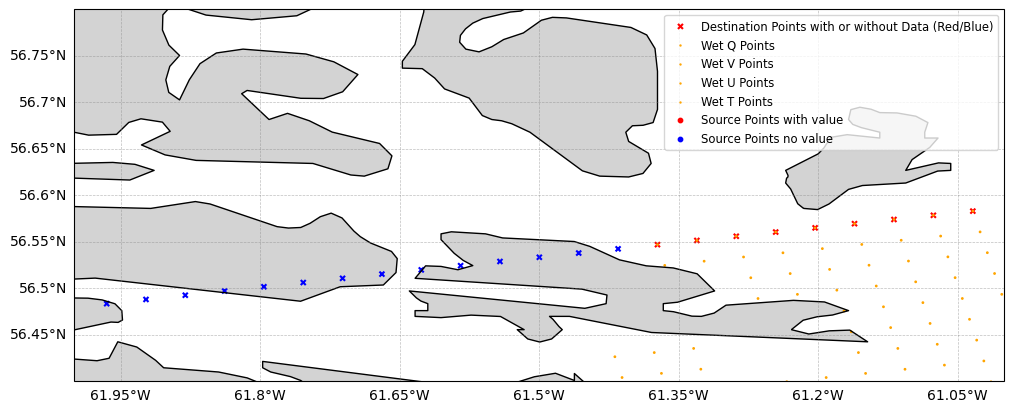

In [23]:
north_bound.plot_regridding_information([-62,-61,56.4,56.8],topo)

In [18]:
report = north_bound.check_source_points_on_dest_nans_over_ocean(topo, -1)
report

{}

In [7]:
info["south"]["analysis_obj"].check_source_points_on_dest_nans_over_ocean(topo)

{1087: {'dest_point': 1087,
  'source_points': <xarray.DataArray 'col' (n_s: 4)>
  array([4245, 4246, 4687, 4688], dtype=int32)
  Dimensions without coordinates: n_s,
  'source_vals': [nan, nan, nan, 2002.4210205078125]},
 1088: {'dest_point': 1088,
  'source_points': <xarray.DataArray 'col' (n_s: 4)>
  array([4245, 4246, 4687, 4688], dtype=int32)
  Dimensions without coordinates: n_s,
  'source_vals': [nan, nan, nan, 2002.4210205078125]},
 1089: {'dest_point': 1089,
  'source_points': <xarray.DataArray 'col' (n_s: 4)>
  array([4246, 4247, 4688, 4689], dtype=int32)
  Dimensions without coordinates: n_s,
  'source_vals': [nan,
   2005.3885498046875,
   2002.4210205078125,
   2000.0233154296875]},
 1090: {'dest_point': 1090,
  'source_points': <xarray.DataArray 'col' (n_s: 4)>
  array([4246, 4247, 4688, 4689], dtype=int32)
  Dimensions without coordinates: n_s,
  'source_vals': [nan,
   2005.3885498046875,
   2002.4210205078125,
   2000.0233154296875]}}

In [100]:
np.where(north_bound.regridded_ds[north_bound.regrid_var_name][0, -35].isnull())

(array([414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 496,
        497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509,
        510, 511, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521, 522,
        523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535,
        536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548,
        549, 550, 551, 552, 553, 554, 555, 928, 929, 930, 931, 932, 933,
        934, 935, 936, 937, 938, 939, 940, 941, 942]),)

In [4]:
keys = ["north","south","east"]
info = {}
for key in keys:
    info[key] = {
        "weights": xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/{key}_weights.nc"),
        "raw_ds":xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_interpolated_data/DIC_{key}_vfilled.nc"),
        "regridded_ds":xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/DIC_{key}_regridded.nc"),
       
    }
    info[key]["analysis_obj"] =  ra.RegriddingAnalysis(raw_ds = info[key]["raw_ds"],regridded_ds=info[key]["regridded_ds"],weights = info[key]["weights"],  regrid_var_name = "__xarray_dataarray_variable__")




In [22]:
from pathlib import Path
output_folder = Path("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_masked_interpolated_data")
for key in keys:
    source_mask = info[key]["analysis_obj"].generate_source_mask()
    dest_mask =  info[key]["analysis_obj"].generate_boundary_dest_mask(topo)
    dest_mask = xr.Dataset({
    "mask": (["index"], dest_mask)
    })
    source_mask.name = "mask"
    source_mask.to_netcdf(output_folder/f"source_mask_{key}.nc")
    dest_mask.to_netcdf(output_folder/f"dest_mask_{key}.nc")

In [21]:
type(dest_mask)

list

In [19]:
s

<xarray.DataArray 'Mask' (nlat: 293, nlon: 489)>
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    z_t      float32 500.0
    ULONG    (nlat, nlon) float64 ...
    ULAT     (nlat, nlon) float64 ...
    TLONG    (nlat, nlon) float64 ...
    TLAT     (nlat, nlon) float64 ...
    time     object 2000-02-01 00:00:00
Dimensions without coordinates: nlat, nlon